# Ⅰ第4回 演習2 5 回回して「差がある」と言えるか

**問い**：演習1 の MLP と CNN の差は，乱数の種（シード）を変えても残るか．

演習1 で自分が書いた③〜⑫と同じ手順を関数 `run` にまとめてある（`common/mydata.py`）．MLP と CNN をシード 0〜4 で 5 回ずつ回す．1 回 1〜数秒．
乱数の使い方が少し違うので，シード 0 の値が演習1 と一致しないことがある．
シードを変えると，**データの分け方・重みの初期値・ミニバッチの順** が変わる．写真とモデルの形は変わらない．

## (0) 番号の設定

In [1]:
# ===== (0) 番号の設定 =====
MEMBER_NO = 2                 # ← グループ内の自分の番号 (1〜5)．presenter はこの番号の順に演習ごとに交代する

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/niirowakana/AI_TD


## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．

- CNN の 5 回のテスト正解率は，一番低い回と高い回で何ポイント離れるか：15ポイント
- 5 回の平均で，CNN と MLP に「差がある」と言えるか：言えない

## (確認) 差の判定

授業ページの「演習2」を読んでから答える．**全問正解すると先へ進める**（ちがうとヒントが出る）．

**Q1**　シードを変えると変わらないものはどれか
- ア データの分け方
- イ 重みの初期値
- ウ 写真そのもの

**Q2**　テスト画像が 30 枚のとき，1 枚の正解・不正解でテスト正解率は何ポイント動くか
- ア 1 ポイント
- イ 約 3.3 ポイント
- ウ 30 ポイント

**Q3**　平均の差 ÷ 標準偏差 が 0.5 だった．どう判定するか
- ア 差がある
- イ 差があるとは言えない
- ウ 標準偏差が小さいので信じられる

In [2]:
from common.todo import checkpoint, quiz_check
# ▼ 下の " " の中に，ア・イ・ウのどれかを書いて実行する
Q1 = "ウ"
Q2 = "イ"
Q3 = "イ"
quiz_check({    # 2 つ目の値は答え合わせ用の暗号（答えは書いていない）
    "Q1": (Q1, "eb47a8e6", "シードで変わるのは分け方・初期値・順．写真は同じ"),
    "Q2": (Q2, "af2c0979", "100 ÷ 30 ≒ 3.3．テストが少ないと 1 枚で大きく動く"),
    "Q3": (Q3, "d0859473", "差がばらつきの半分しかない．1 未満なら「差があるとは言えない」"),
})

Q1：正解．シードで変わるのは分け方・初期値・順．写真は同じ
Q2：正解．100 ÷ 30 ≒ 3.3．テストが少ないと 1 枚で大きく動く
Q3：正解．差がばらつきの半分しかない．1 未満なら「差があるとは言えない」
全問正解．実験に進んでよい


## (1) MLP と CNN をシード 0〜4 で回す

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from common.device import get_device
from common.logger import ResultLogger
from common.mydata import image_dir, run, diff_ratio, verdict
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

device = get_device()
IMAGE_DIR = image_dir()
SEEDS = [0, 1, 2, 3, 4]
logger = ResultLogger(None, f"member{MEMBER_NO}", course="c1", day="d4", exercise="ex2", device=device)
rows = []
for kind in ["MLP", "CNN"]:
    for seed in SEEDS:
        r = run(kind, seed=seed, root=IMAGE_DIR, device=device)
        logger.log_many({k: r[k] for k in ["test_acc", "val_acc_best", "train_sec"]}, condition=f"{IMAGE_DIR.name}_{kind}", seed=seed)
        rows.append({"モデル": kind, "シード": seed, "テスト正解率": r["test_acc"] * 100, "学習時間(秒)": r["train_sec"]})
        print(f"{kind} シード {seed}：テスト正解率 {r['test_acc'] * 100:.1f}%  ({r['train_sec']:.1f} 秒)")
df = pd.DataFrame(rows)
print(f"テストは {r['n_test']} 枚．1 枚で {100 / r['n_test']:.1f} ポイント動く")

MLP シード 0：テスト正解率 46.7%  (7.1 秒)
MLP シード 1：テスト正解率 46.7%  (2.0 秒)
MLP シード 2：テスト正解率 26.7%  (2.5 秒)
MLP シード 3：テスト正解率 40.0%  (2.4 秒)
MLP シード 4：テスト正解率 60.0%  (2.4 秒)
CNN シード 0：テスト正解率 80.0%  (3.6 秒)
CNN シード 1：テスト正解率 46.7%  (1.1 秒)
CNN シード 2：テスト正解率 40.0%  (1.6 秒)
CNN シード 3：テスト正解率 66.7%  (1.1 秒)
CNN シード 4：テスト正解率 73.3%  (1.5 秒)
テストは 15 枚．1 枚で 6.7 ポイント動く


## (2) 平均・標準偏差と，差 ÷ 標準偏差

モデル   MLP   CNN
シード            
0    46.7  80.0
1    46.7  46.7
2    26.7  40.0
3    40.0  66.7
4    60.0  73.3

       平均  標準偏差    最小    最大
モデル                        
CNN  61.3  17.3  40.0  80.0
MLP  44.0  12.1  26.7  60.0

平均の差（CNN − MLP）+17.3 ポイント ÷ 標準偏差 14.9 = 1.2 → どちらとも言えない（回数を増やして確かめる）
シード 0 だけなら：CNN − MLP = +33.3 ポイント


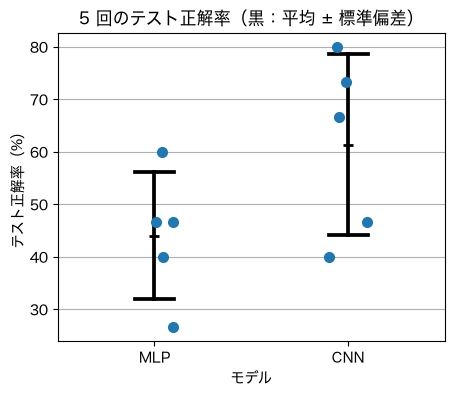

In [4]:
table = df.pivot(index="シード", columns="モデル", values="テスト正解率")[["MLP", "CNN"]]
print(table.round(1).to_string())
print()
print(df.groupby("モデル")["テスト正解率"].agg(平均="mean", 標準偏差="std", 最小="min", 最大="max").round(1).to_string())

diff, sd, ratio = diff_ratio(table["MLP"], table["CNN"])
print(f"\n平均の差（CNN − MLP）{diff:+.1f} ポイント ÷ 標準偏差 {sd:.1f} = {ratio:.1f} → {verdict(ratio)}")
print(f"シード 0 だけなら：CNN − MLP = {table.loc[0, 'CNN'] - table.loc[0, 'MLP']:+.1f} ポイント")

plt.figure(figsize=(5, 4))
sns.stripplot(data=df, x="モデル", y="テスト正解率", size=8, jitter=0.1)
sns.pointplot(data=df, x="モデル", y="テスト正解率", errorbar="sd", color="black", markers="_", capsize=0.2, linestyle="none")
plt.title("5 回のテスト正解率（黒：平均 ± 標準偏差）"); plt.ylabel("テスト正解率（%）"); plt.grid(True, axis="y")
plt.show()

## ✋ 止まる 1：ここから先へは，グループ全員がそろってから進む

**問い**：メンバーの中で「差がある」と言えた人と言えなかった人がいたか．データの何が違ったか

1. **presenter**（この演習の担当）：問いを読み上げ，話し合いを進める．全員の考えを聞き，根拠を含めて答えを 1〜2 文にまとめる
2. **全員**：自分の (2) の表とグラフを見せ，クラス・枚数・差 ÷ 標準偏差を言う．根拠になる所：(2) の標準偏差と，1 枚で何ポイント動くか
3. 全員が下のセルの `CP1 = ""` に答えを書いて実行する（10 文字未満だと止まる）

In [6]:
# 問い：メンバーの中で「差がある」と言えた人と言えなかった人がいたか．データの何が違ったか
# ▼ グループで決めた答えを " " の中に書く（1〜2 文）
CP1 = "差があると言えた人と言えなかった人がいた。私の靴の写真はネットの画像で背景がばらばらなうえテストが15枚しかなく、1枚で6.7ポイント動いて標準偏差が大きくなったので差があるとは言えなかった。差があると言えた人は、クラスの見た目の違いがはっきりしていて、ばらつきが小さかった。"
checkpoint(CP1, "止まる 1")

止まる 1 OK：差があると言えた人と言えなかった人がいた。私の靴の写真はネットの画像で背景がばらばらなうえテストが15枚しかなく、1枚で6.7ポイント動いて標準偏差が大きくなったので差があるとは言えなかった。差があると言えた人は、クラスの見た目の違いがはっきりしていて、ばらつきが小さかった。


## (3) 第1〜3回から持ち越した問いの答え合わせ

教員が同じ条件で回した値（第2回は 3 回．ほかは 5 回）．

In [7]:
carry = [   # (問い, 比べたもの, 指標, A の値, B の値)
    ("第1回 ケーブル画像", "MLP → CNN", "テスト正解率(%)", [83.3, 76.7, 76.7, 83.3, 80.0], [80.0, 73.3, 83.3, 90.0, 90.0]),
    ("第2回 映画レビュー", "MLP → Transformer", "テスト正解率(%)", [80.40, 80.56, 80.67], [80.94, 80.67, 81.05]),
    ("第3回 正則化", "なし → Dropout", "検証正解率の最高値(%)", [81.20, 81.98, 81.42, 82.12, 81.00], [81.65, 82.41, 82.14, 82.73, 81.26]),
    ("第3回 正則化", "なし → 早期終了", "検証損失", [0.99, 0.94, 0.96, 0.97, 0.96], [0.57, 0.56, 0.57, 0.55, 0.56]),
]
for name, pair, metric, a, b in carry:
    d, s, r = diff_ratio(a, b)
    print(f"{name}｜{pair}｜{metric}：差 {d:+.2f} ÷ 標準偏差 {s:.2f} = {r:.1f} → {verdict(r)}")

第1回 ケーブル画像｜MLP → CNN｜テスト正解率(%)：差 +3.32 ÷ 標準偏差 5.53 = 0.6 → 差があるとは言えない
第2回 映画レビュー｜MLP → Transformer｜テスト正解率(%)：差 +0.34 ÷ 標準偏差 0.17 = 2.0 → 差がある
第3回 正則化｜なし → Dropout｜検証正解率の最高値(%)：差 +0.49 ÷ 標準偏差 0.54 = 0.9 → 差があるとは言えない
第3回 正則化｜なし → 早期終了｜検証損失：差 -0.40 ÷ 標準偏差 0.01 = 28.4 → 差がある


## (4) 考察（提出）

このセルをダブルクリックして，＿＿ に書き込む（それぞれ 1〜2 文）．

1. 予測と比べて，当たったこと・外れたこと：CNN の 5 回のテスト正解率は 15 ポイント離れると予測したが，実際は最低 40.0%・最高 80.0% で 40 ポイントも離れ，予想よりずっと大きくぶれた．CNN と MLP に差があるとは言えないと予測したが，差 ÷ 標準偏差は 1.2 で「どちらとも言えない」という判定になり，ほぼ当たった．
2. 自分のデータで，CNN と MLP に差があると言えたか．シード 0 だけの結論と同じだったか：5 回の平均は CNN 61.3%・MLP 44.0% で差は 17.3 ポイントあったが，標準偏差が 14.9 ポイントと大きく，差 ÷ 標準偏差は 1.2 で「どちらとも言えない（回数を増やして確かめる）」という判定だった．シード 0 だけでは CNN − MLP = +33.3 ポイントで CNN がはっきり良く見えたが，シード 1 では両方 46.7% で差が 0 になるなど，1 回だけの結論は当てにならなかった．また MLP の平均 44.0% は 2 クラスの当てずっぽう（50%）より低く，ネットから集めた背景や撮り方がばらばらの靴の写真を，MLP はほとんど学習できていなかった．
3. (3) で，第1回（差 3.3 ポイント）と第2回（差 0.4 ポイント）の判定が逆になったのはなぜか．テストの枚数に注目して書く：第1回のケーブル画像はテストが 30 枚しかなく，1 枚で 3.3 ポイント動くので，シードを変えると正解率が大きくぶれ，標準偏差が 5.5 ポイントもあった．差の 3.3 ポイントはこのぶれより小さいので「差があるとは言えない」になった．第2回の映画レビューはテストが 1,821 文あり，1 文では 0.05 ポイントしか動かないので，標準偏差が 0.17 ポイントと小さく，0.4 ポイントの差でもぶれの 2 倍あって「差がある」と言えた．差の大きさだけでなく，テストの枚数で決まるばらつきと比べないと判定できない．